# Shift Cipher: Implementation, Testing, and Cryptanalysis

## Objective

The shift cipher is a classical substitution cipher in which each letter of the plaintext is shifted by a fixed number of positions in the alphabet to produce ciphertext.

This notebook explores the mathematical foundation, implementation, testing, and security weaknesses of the shift cipher. It also demonstrates an optional extension that allows numerical digits to be shifted.

### Learning objectives

- Understand the mathematical principles behind encryption and decryption.
- Implement the shift cipher using Python without external cryptography libraries.
- Test the implementation against normal inputs and edge cases.
- Extend the cipher to support numerical digits.
- Demonstrate brute-force attacks, known-plaintext attacks, and frequency analysis.
- Evaluate the algorithm's time complexity and security limitations.

### Scope

This is an educational implementation intended to demonstrate classical cryptography and basic cryptanalysis. The shift cipher is not suitable for protecting sensitive information in real-world applications.

## 1. Mathematical Foundation

The shift cipher replaces each letter with another letter located a fixed number of positions ahead in the alphabet.

We assign each letter a numerical value:

- A = 0, B = 1, C = 2, ..., Z = 25.

Let:

- \(P\) represent the numerical value of a plaintext letter.
- \(C\) represent the numerical value of the corresponding ciphertext letter.
- \(k\) represent the encryption key.

### Encryption

The encryption formula is:

\[
C = (P+k)\bmod 26
\]

### Decryption

The decryption formula is:

\[
P = (C-k)\bmod 26
\]

The modulo operation ensures that the result remains within the range 0–25, allowing the alphabet to wrap around.

**Example:** Encrypt the letter Z using key 3.

\[
C=(25+3)\bmod 26=2
\]

The numerical value 2 corresponds to C. Therefore, Z becomes C.

Similarly, decrypting C using key 3 gives:

\[
P=(2-3)\bmod 26=25
\]

The result corresponds to Z.

### Key properties

- A key of 0 leaves the letters unchanged.
- A key of 26 produces the same result as a key of 0.
- Negative keys shift letters backwards.
- Keys can be reduced modulo 26 because the alphabet contains 26 letters.

In the standard implementation, only ASCII English letters are shifted. Digits, spaces, punctuation, and other characters remain unchanged.

In [38]:
def shift_cipher(text, key, decrypt=False, shift_digits=False):
    if not isinstance(key, int) or isinstance(key, bool):
        raise TypeError("Key must be an integer.")

    shift = -key if decrypt else key
    result = ""

    for char in text:
        if char.isascii() and char.isalpha():
            base = ord('A') if char.isupper() else ord('a')
            position = ord(char) - base
            new_position = (position + shift) % 26
            result += chr(base + new_position)

        elif char.isascii() and char.isdigit() and shift_digits:
            position = int(char)
            new_position = (position + shift) % 10
            result += str(new_position)

        else:
            result += char

    return result


def encrypt(text, key, shift_digits=False):
    return shift_cipher(text, key, shift_digits=shift_digits)


def decrypt(text, key, shift_digits=False):
    return shift_cipher(
        text, key, decrypt=True, shift_digits=shift_digits
    )

## 2. Understanding the Implementation

The implementation uses Python's built-in functions to perform character manipulation.

- `ord()` converts a character into its numerical Unicode value.
- `chr()` converts a numerical value back into a character.
- `% 26` ensures that letter positions wrap around the alphabet.
- `% 10` ensures that digit positions wrap around from 9 to 0.
- `isupper()` helps preserve the case of English letters.
- `isascii()` restricts the shifting logic to ASCII characters.
- `decrypt` determines whether the key is applied forwards or backwards.
- `shift_digits` is an optional parameter that is `False` by default.

When `shift_digits=False`, the implementation behaves as a standard shift cipher. When `shift_digits=True`, ASCII digits are also shifted using modulo 10.

The same implementation supports both modes, avoiding unnecessary duplication of the encryption and decryption logic.

The key validation also rejects Boolean values, even though Python treats `True` and `False` as integers.

In [39]:
message = "Hello, World! 123"
key = 3

ciphertext = encrypt(message, key)
plaintext = decrypt(ciphertext, key)

print("Original message:", message)
print("Encrypted message:", ciphertext)
print("Decrypted message:", plaintext)

Original message: Hello, World! 123
Encrypted message: Khoor, Zruog! 123
Decrypted message: Hello, World! 123


## 3. Testing Standard Encryption and Decryption

The example encrypts the message using a key of 3. Each English letter moves three positions forward, while spaces, punctuation, and digits remain unchanged.

Decryption applies the same key in the opposite direction, recovering the original message.

A fundamental correctness property is:

\[
D_k(E_k(P))=P
\]

Here, \(E_k\) represents encryption, \(D_k\) represents decryption, and \(P\) represents the original plaintext.

If decryption successfully restores the original message, it demonstrates that the two operations are consistent for that input.

In [40]:
assert encrypt("XYZ", 3) == "ABC"
assert decrypt("ABC", 3) == "XYZ"

assert encrypt("Hello", 0) == "Hello"
assert encrypt("Hello", 26) == "Hello"
assert encrypt("Hello", 29) == "Khoor"
assert encrypt("Hello", -3) == "Ebiil"

assert encrypt("", 5) == ""
assert encrypt("123 !@#", 7) == "123 !@#"

message = "Cryptography!"
assert decrypt(encrypt(message, 11), 11) == message

try:
    encrypt("Hello", 2.5)
except TypeError:
    pass
else:
    raise AssertionError("A non-integer key should be rejected.")

print("All standard-mode tests passed.")

All standard-mode tests passed.


## 4. Edge-Case Testing

Edge-case testing checks whether an implementation behaves correctly under unusual or boundary conditions.

The tests cover:

- **Alphabet wraparound:** Z shifts back to A when the key is 3.
- **Zero key:** No change occurs when the key is 0.
- **Equivalent keys:** A key of 26 produces no change.
- **Large and negative keys:** The modulo operation handles keys outside the usual range.
- **Empty input:** An empty string remains empty.
- **Non-letter characters:** Digits, spaces, and punctuation are preserved in standard mode.
- **Round-trip correctness:** Decryption recovers the original message.
- **Invalid key types:** Non-integer keys are rejected.

Assertions automatically raise an error if a test fails. If every assertion passes, the final message confirms that the tests were successful.

In [41]:

assert encrypt("XYZ", 3) == "ABC"
assert decrypt("ABC", 3) == "XYZ"

assert encrypt("Hello", 0) == "Hello"
assert encrypt("Hello", 26) == "Hello"
assert encrypt("Hello", 29) == "Khoor"
assert encrypt("Hello", -3) == "Ebiil"

assert encrypt("", 5) == ""
assert encrypt("123 !@#", 7) == "123 !@#"

assert decrypt(encrypt("Cryptography!", 11), 11) == "Cryptography!"

try:
    encrypt("Hello", 2.5)
except TypeError:
    pass
else:
    raise AssertionError("Non-integer keys should raise TypeError.")

print("All edge-case tests passed!")


All edge-case tests passed!


## 5. Extension: Supporting Numerical Digits

The conventional shift cipher operates on a 26-letter English alphabet. Numerical digits are not part of this alphabet and therefore remain unchanged in the standard mode.

As an optional extension, this implementation supports shifting digits from 0 to 9.

### Digit-shifting formula

For a numerical digit \(D\), encryption becomes:

\[
C_d=(D+k)\bmod 10
\]

Decryption becomes:

\[
D=(C_d-k)\bmod 10
\]

Unlike letters, which wrap around every 26 positions, digits wrap around every 10 positions.

This is a custom extension rather than a property of the conventional Caesar cipher.

### Example

Using the key 3:

- The letter H becomes K.
- The digit 9 becomes 2.
- The digit 3 becomes 6.
- The digit 0 becomes 3.

Digit shifting is disabled by default. It must be explicitly enabled using `shift_digits=True`.

In [42]:
message = "Meet me at 9:30!"
key = 3

standard = encrypt(message, key)
extended = encrypt(message, key, shift_digits=True)

print("Original:       ", message)
print("Standard mode:  ", standard)
print("Extended mode:  ", extended)

Original:        Meet me at 9:30!
Standard mode:   Phhw ph dw 9:30!
Extended mode:   Phhw ph dw 2:63!


# Extension Tests

In [43]:
message = "Hello 123! XYZ 789"

standard = encrypt(message, 3)
extended = encrypt(message, 3, shift_digits=True)

assert standard == "Khoor 123! ABC 789"
assert extended == "Khoor 456! ABC 012"

assert decrypt(standard, 3) == message
assert decrypt(extended, 3, shift_digits=True) == message

assert encrypt("789", 3, shift_digits=True) == "012"
assert encrypt("012", -3, shift_digits=True) == "789"
assert encrypt("123", 10, shift_digits=True) == "123"

print("All digit-extension tests passed.")


All digit-extension tests passed.


## 6. Comparing the Two Modes

Both modes use the same encryption and decryption functions, but they process numerical digits differently.

| Feature | Standard mode | Extended mode |
|---|---|---|
| English letters | Shifted modulo 26 | Shifted modulo 26 |
| Digits | Unchanged | Shifted modulo 10 |
| Spaces | Preserved | Preserved |
| Punctuation | Preserved | Preserved |
| Default setting | Yes | No |

The tests demonstrate that the standard mode preserves digits, while the extended mode shifts them. Both modes must correctly recover the original message when decrypted with the matching settings.

**Important:** Encryption and decryption must use the same `shift_digits` setting. Otherwise, the digits may not be restored correctly.

## 7. Cryptanalysis I: Brute-Force Attack

A brute-force attack attempts every possible key until a plausible plaintext is found.

For the standard shift cipher, the effective key space contains only 26 distinct shifts: 0 through 25. Any integer key is equivalent to one of these shifts for English letters.

An attacker does not need to know the original key in advance. Instead, the attacker generates a candidate plaintext for every possible key.

### Complexity

Let \(n\) represent the length of the ciphertext.

- Each decryption takes \(O(n)\) time.
- There are 26 candidate keys.
- Total time complexity is \(O(26n)=O(n)\), since 26 is a constant.
- Space complexity is \(O(26n)=O(n)\) when all candidate plaintexts are stored.

Brute-force enumeration does not automatically identify the correct plaintext. A person or an additional scoring method must determine which candidate is plausible.

In [44]:
def brute_force_attack(ciphertext, shift_digits=False):
    results = []

    for key in range(26):
        candidate = decrypt(
            ciphertext, key, shift_digits=shift_digits
        )
        results.append((key, candidate))

    return results


message = "Meet me at the library"
key = 7

ciphertext = encrypt(message, key)

print("Ciphertext:", ciphertext)
print()

for candidate_key, candidate_text in brute_force_attack(ciphertext):
    print(f"Key {candidate_key:2}: {candidate_text}")

Ciphertext: Tlla tl ha aol spiyhyf

Key  0: Tlla tl ha aol spiyhyf
Key  1: Skkz sk gz znk rohxgxe
Key  2: Rjjy rj fy ymj qngwfwd
Key  3: Qiix qi ex xli pmfvevc
Key  4: Phhw ph dw wkh oleudub
Key  5: Oggv og cv vjg nkdtcta
Key  6: Nffu nf bu uif mjcsbsz
Key  7: Meet me at the library
Key  8: Ldds ld zs sgd khaqzqx
Key  9: Kccr kc yr rfc jgzpypw
Key 10: Jbbq jb xq qeb ifyoxov
Key 11: Iaap ia wp pda hexnwnu
Key 12: Hzzo hz vo ocz gdwmvmt
Key 13: Gyyn gy un nby fcvluls
Key 14: Fxxm fx tm max ebuktkr
Key 15: Ewwl ew sl lzw datjsjq
Key 16: Dvvk dv rk kyv czsirip
Key 17: Cuuj cu qj jxu byrhqho
Key 18: Btti bt pi iwt axqgpgn
Key 19: Assh as oh hvs zwpfofm
Key 20: Zrrg zr ng gur yvoenel
Key 21: Yqqf yq mf ftq xundmdk
Key 22: Xppe xp le esp wtmclcj
Key 23: Wood wo kd dro vslbkbi
Key 24: Vnnc vn jc cqn urkajah
Key 25: Ummb um ib bpm tqjzizg


In [45]:
message = "Meet me at the library"
key = 7

ciphertext = encrypt(message, key)
results = brute_force_attack(ciphertext)

assert len(results) == 26
assert results[0][0] == 0
assert results[-1][0] == 25
assert (key, message) in results

print("Brute-force attack tests passed.")

Brute-force attack tests passed.


## Brute Force in Extended Mode


In [46]:
message = "Meet me at 9:30!"
key = 7

ciphertext = encrypt(message, key, shift_digits=True)
results = brute_force_attack(ciphertext, shift_digits=True)

assert (key, message) in results

print("Extended-mode brute-force test passed.")

Extended-mode brute-force test passed.


## 8. Interpreting Brute-Force Results

The attack produces 26 candidate decryptions, one for each key from 0 to 25.

The correct key and original message should appear among the candidates if the ciphertext was generated using the same mode and an equivalent key.

The same search covers the intended key range in the extended mode, provided the key is restricted to 0–25. If arbitrary integer keys are permitted and both letters and digits are shifted, the combined transformation repeats every 130 shifts because the periods are 26 and 10. This does not make the cipher secure; it only changes the mathematical period of the extended transformation.

The central weakness remains the small number of possible transformations.

## 9. Cryptanalysis II: Known-Plaintext Attack

A known-plaintext attack assumes that an attacker knows at least one plaintext character and its corresponding ciphertext character.

The attacker uses this pair to calculate the encryption key.

For letters, the encryption formula is:

\[
C=(P+k)\bmod 26
\]

Rearranging the equation gives:

\[
k=(C-P)\bmod 26
\]

### Example

Suppose the known plaintext letter is H and the corresponding ciphertext letter is K.

Using A = 0, B = 1, ..., Z = 25:

- H has value 7.
- K has value 10.

Therefore:

\[
k=(10-7)\bmod 26=3
\]

The recovered key is 3.

One valid letter pair is sufficient to recover the key for this cipher because every letter uses the same fixed shift. The attack can then decrypt the remaining ciphertext.

In [47]:
def recover_key(known_plaintext, known_ciphertext):
    if not known_plaintext or not known_ciphertext:
        raise ValueError("Inputs must not be empty.")

    if len(known_plaintext) != len(known_ciphertext):
        raise ValueError("Inputs must have equal lengths.")

    for plain_char, cipher_char in zip(
        known_plaintext, known_ciphertext
    ):
        if not (
            plain_char.isascii()
            and plain_char.isalpha()
            and cipher_char.isascii()
            and cipher_char.isalpha()
        ):
            raise ValueError("Inputs must contain ASCII letters only.")

        base_plain = ord('A') if plain_char.isupper() else ord('a')
        base_cipher = ord('A') if cipher_char.isupper() else ord('a')

        plain_value = ord(plain_char) - base_plain
        cipher_value = ord(cipher_char) - base_cipher

        return (cipher_value - plain_value) % 26

In [48]:
known_plaintext = "H"
known_ciphertext = "K"

recovered_key = recover_key(
    known_plaintext, known_ciphertext
)

secret_message = "Secret message"
ciphertext = encrypt(secret_message, recovered_key)

print("Recovered key:", recovered_key)
print("Ciphertext:", ciphertext)
print("Decrypted message:", decrypt(ciphertext, recovered_key))

Recovered key: 3
Ciphertext: Vhfuhw phvvdjh
Decrypted message: Secret message


### Testing Key Recovery

The test verifies that a known plaintext-ciphertext pair recovers the correct shift value.

It also checks that invalid inputs, such as empty strings, unequal lengths, or non-letter characters, are rejected.

This is a useful security demonstration because the attack does not need to try all 26 keys. Under the Shift Cipher's assumptions, a single corresponding letter pair is sufficient to recover the key.

The test validates the intended input handling and the correctness of the recovered key for the selected example.

In [49]:
assert recover_key("H", "K") == 3
assert recover_key("A", "A") == 0
assert recover_key("Z", "C") == 3
assert recover_key("A", "Z") == 25

for plain, cipher in [("", "A"), ("AB", "C"), ("A", "1")]:
    try:
        recover_key(plain, cipher)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid input should be rejected.")

print("Known-plaintext attack tests passed.")

Known-plaintext attack tests passed.


## 10. Interpreting the Known-Plaintext Attack

The function recovers the key using the first valid letter pair. It checks that the inputs are non-empty, have equal lengths, and contain only ASCII English letters.

Because the shift cipher uses a single fixed key, a valid plaintext-ciphertext letter pair reveals the shift. Once the key is known, the attacker can decrypt the complete message.

This implementation demonstrates the core attack. It does not check whether every additional character pair is consistent with the recovered key; that could be added as a validation improvement.

The attack illustrates why the shift cipher is vulnerable even when the attacker cannot try every key manually.

## 11. Cryptanalysis III: Frequency Analysis

Frequency analysis examines how often individual letters occur in a piece of text.

In English, letters such as E, T, A, O, I, and N generally appear more frequently than letters such as Q, X, and Z.

The shift cipher replaces each letter consistently. As a result, it preserves the frequency distribution of the letters, although the letters themselves change.

For example, if E is the most common letter in a plaintext, the letter that replaces E may also be unusually common in the ciphertext.

### Limitations

Frequency analysis works best on sufficiently long pieces of text. Short messages may not contain enough data to produce a reliable distribution.

It is also language-dependent: the expected letter frequencies differ across languages and writing styles.

Frequency analysis does not guarantee the correct key. It provides statistical evidence that can help rank possible decryptions.

In [50]:
from collections import Counter
import string


def letter_frequency(text):
    letters = [
        char.upper()
        for char in text
        if char.isascii() and char.isalpha()
    ]

    counts = Counter(letters)
    total = len(letters)

    if total == 0:
        return {letter: 0.0 for letter in string.ascii_uppercase}

    return {
        letter: counts.get(letter, 0) / total * 100
        for letter in string.ascii_uppercase
    }


sample = "THE QUICK BROWN FOX JUMPS OVER THE LAZY DOG " * 5
ciphertext = encrypt(sample, 3)

frequencies = letter_frequency(ciphertext)

for letter, percentage in sorted(
    frequencies.items(), key=lambda item: item[1], reverse=True
):
    print(f"{letter}: {percentage:.2f}%")

R: 11.43%
H: 8.57%
K: 5.71%
U: 5.71%
W: 5.71%
X: 5.71%
A: 2.86%
B: 2.86%
C: 2.86%
D: 2.86%
E: 2.86%
F: 2.86%
G: 2.86%
I: 2.86%
J: 2.86%
L: 2.86%
M: 2.86%
N: 2.86%
O: 2.86%
P: 2.86%
Q: 2.86%
S: 2.86%
T: 2.86%
V: 2.86%
Y: 2.86%
Z: 2.86%


## 12. Visualising Letter Frequencies

The `letter_frequency()` function counts ASCII English letters and calculates each letter's percentage of the total letters in the text.

Spaces, digits, punctuation, and other non-letter characters are excluded from the calculation.

The bar chart makes it easier to identify common and uncommon letters in the ciphertext. Comparing the distribution with expected English letter frequencies can help an attacker identify likely shifts.

The chart demonstrates the statistical weakness of a simple substitution system: although the letters are shifted, their relative frequencies are preserved.

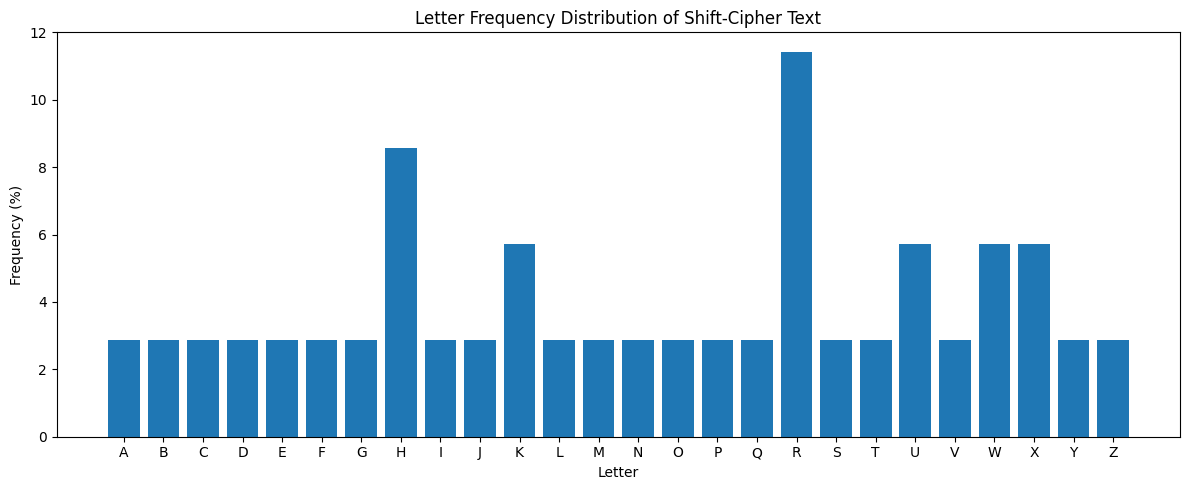

In [51]:
import matplotlib.pyplot as plt

letters = list(frequencies.keys())
percentages = list(frequencies.values())

plt.figure(figsize=(12, 5))
plt.bar(letters, percentages)
plt.xlabel("Letter")
plt.ylabel("Frequency (%)")
plt.title("Letter Frequency Distribution of Shift-Cipher Text")
plt.tight_layout()
plt.show()

## 13. Ranking Candidates with English Letter Frequencies

Instead of examining all 26 brute-force candidates manually, we can estimate which candidate most closely resembles English text.

One method uses the chi-squared statistic:

\[
\chi^2=\sum_{i=1}^{26}\frac{(O_i-E_i)^2}{E_i}
\]

Where:

- \(O_i\) is the observed count of a letter in the candidate text.
- \(E_i\) is the expected count based on English letter frequencies.

A lower score indicates that the observed distribution is closer to the expected English distribution.

This is a statistical heuristic, not a guarantee. Short messages, names, technical text, and non-English messages can produce misleading rankings.

In [52]:
ENGLISH_FREQUENCIES = {
    'A': 8.167, 'B': 1.492, 'C': 2.782, 'D': 4.253,
    'E': 12.702, 'F': 2.228, 'G': 2.015, 'H': 6.094,
    'I': 6.966, 'J': 0.153, 'K': 0.772, 'L': 4.025,
    'M': 2.406, 'N': 6.749, 'O': 7.507, 'P': 1.929,
    'Q': 0.095, 'R': 5.987, 'S': 6.327, 'T': 9.056,
    'U': 2.758, 'V': 0.978, 'W': 2.360, 'X': 0.150,
    'Y': 1.974, 'Z': 0.074
}


def english_score(text):
    letters = [
        char.upper()
        for char in text
        if char.isascii() and char.isalpha()
    ]

    if not letters:
        return float("inf")

    counts = Counter(letters)
    total = len(letters)
    score = 0

    for letter, percentage in ENGLISH_FREQUENCIES.items():
        observed = counts.get(letter, 0)
        expected = total * percentage / 100

        if expected > 0:
            score += (observed - expected) ** 2 / expected

    return score


def rank_candidates(ciphertext):
    candidates = []

    for key in range(26):
        candidate = decrypt(ciphertext, key)
        candidates.append((english_score(candidate), key, candidate))

    return sorted(candidates)


message = "The quick brown fox jumps over the lazy dog. " * 10
ciphertext = encrypt(message, 7)

for score, key, candidate in rank_candidates(ciphertext)[:5]:
    print(f"Key {key:2} | Score {score:8.2f} | {candidate[:60]}")

Key  7 | Score  1093.19 | The quick brown fox jumps over the lazy dog. The quick brown
Key 13 | Score  1229.35 | Nby kocwe vliqh zir dogjm ipyl nby futs xia. Nby kocwe vliqh
Key 19 | Score  1291.84 | Hvs eiwqy pfckb tcl xiadg cjsf hvs zonm rcu. Hvs eiwqy pfckb
Key 23 | Score  1295.40 | Dro aesmu lbygx pyh tewzc yfob dro vkji nyq. Dro aesmu lbygx
Key  9 | Score  1320.23 | Rfc osgai zpmul dmv hsknq mtcp rfc jyxw bme. Rfc osgai zpmul


## 14. Interpreting Candidate Rankings

The ranking function decrypts the ciphertext with every key and calculates an English-frequency score for each candidate.

Candidates with lower scores are displayed first. A likely plaintext may rank near the top when the ciphertext contains enough ordinary English text.

The method can fail when the ciphertext is too short or when its text distribution differs significantly from typical English. A real cryptanalysis system may combine frequency statistics with dictionary checks, language models, or other evidence.

This example demonstrates how statistical analysis can automate part of the cryptanalysis process.

## 15. Time and Space Complexity

Let \(n\) represent the number of characters in the input text.

| Operation | Time complexity | Space complexity |
|---|---|---|
| Encryption | \(O(n)\) | \(O(n)\) |
| Decryption | \(O(n)\) | \(O(n)\) |
| Brute-force attack | \(O(26n)=O(n)\) | \(O(26n)=O(n)\) |
| Key recovery | \(O(1)\) | \(O(1)\) |
| Letter frequency calculation | \(O(n)\) | \(O(1)\) for the fixed alphabet |
| Candidate ranking | \(O(26n)=O(n)\) | \(O(26n)=O(n)\) when candidates are stored |

The implementation builds new strings, so encryption and decryption require space proportional to the input length.

The brute-force and ranking functions store 26 candidate strings, resulting in \(O(26n)\) space. Since 26 is a constant, this simplifies to \(O(n)\).

Key recovery examines the first letter pair after validating the input, so its core computation takes constant time and space.

## 16. Security Analysis

The shift cipher is useful for learning cryptographic fundamentals, but it has several serious security weaknesses.

### 1. Small key space

There are only 26 distinct shifts for English letters. An attacker can test every possibility easily.

### 2. Preserved letter frequencies

Every plaintext letter is consistently replaced by another letter. This makes statistical attacks possible.

### 3. Vulnerability to known plaintext

A single valid plaintext-ciphertext letter pair reveals the key.

### 4. No authentication or integrity protection

The cipher does not detect whether a message has been modified. It provides neither message authentication nor reliable tamper detection.

### 5. No meaningful modern confidentiality

The algorithm is deterministic and has no protection against the attacks demonstrated in this notebook.

### Effect of digit shifting

Shifting digits as an extension does not turn the algorithm into a secure cryptographic system. It changes how characters are transformed, but the operation remains a simple deterministic shift with a very small set of possibilities under the demonstrated key range.

**Conclusion:** The shift cipher should only be used for education, demonstrations, or simple puzzles. Sensitive information should be protected using modern, vetted cryptographic algorithms and secure implementations.

## 17. Conclusion

This notebook implemented the classical shift cipher from scratch and demonstrated both its standard behaviour and an optional digit-shifting extension.

It also explored several cryptanalysis techniques:

- Brute-force search to enumerate possible keys.
- Known-plaintext analysis to recover the shift.
- Frequency analysis to examine statistical patterns.
- Chi-squared scoring to rank candidate decryptions.

The tests demonstrate the importance of handling edge cases, validating inputs, and checking that decryption restores the original message.

Most importantly, the notebook illustrates the distinction between a correct implementation and a secure cryptographic design. A program can behave exactly as intended and still be easy to attack.

This project establishes a foundation for further exploration of classical cryptography, modern encryption, and cybersecurity analysis.